In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "city_day_cleaned.csv"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-Monsoon"

df["Season"] = df["Month"].apply(get_season)

print("Dataset loaded:", df.shape)
print("Cities:", df["City"].nunique())
print("Available AQI observations:", df["AQI"].notna().sum())


Dataset loaded: (29531, 20)
Cities: 26
Available AQI observations: 24850


In [2]:

city_quality = (
    df.groupby("City")
    .agg(
        Total_Records=("AQI", "size"),
        AQI_Records=("AQI", "count"),
        Average_AQI=("AQI", "mean")
    )
)

city_quality["AQI_Coverage_Percent"] = (
    city_quality["AQI_Records"]
    / city_quality["Total_Records"] * 100
)

city_quality = city_quality.sort_values(
    "AQI_Coverage_Percent",
    ascending=False
)

display(city_quality.round(2))

city_quality.to_csv(TABLES_DIR / "advanced_city_quality.csv")


,Total_Records,AQI_Records,Average_AQI,AQI_Coverage_Percent
City,,,,
Delhi,2009,1999,259.49,99.50
Guwahati,502,495,140.11,98.61
Chandigarh,304,299,96.50,98.36
Aizawl,113,111,34.77,98.23
Jaipur,1114,1094,133.68,98.20
Kochi,162,158,104.28,97.53
Bhopal,289,278,132.83,96.19
Bengaluru,2009,1910,94.32,95.07
Thiruvananthapuram,1112,1052,75.88,94.60


10 cities with highest average AQI


,Average_AQI,Median_AQI,AQI_Records
City,,,
Ahmedabad,452.12,384.5,1334
Delhi,259.49,257.0,1999
Patna,240.78,215.0,1459
Gurugram,225.12,208.0,1453
Lucknow,217.97,198.0,1893
Talcher,172.89,128.5,698
Jorapokhar,159.25,133.0,771
Brajrajnagar,150.28,122.0,713
Kolkata,140.57,94.0,754


10 cities with lowest average AQI


,Average_AQI,Median_AQI,AQI_Records
City,,,
Aizawl,34.77,23.0,111
Shillong,53.80,48.0,205
Coimbatore,73.02,75.0,344
Thiruvananthapuram,75.88,68.0,1052
Ernakulam,92.36,94.0,153
Bengaluru,94.32,86.0,1910
Amaravati,95.30,78.0,841
Chandigarh,96.50,82.0,299
Kochi,104.28,99.0,158


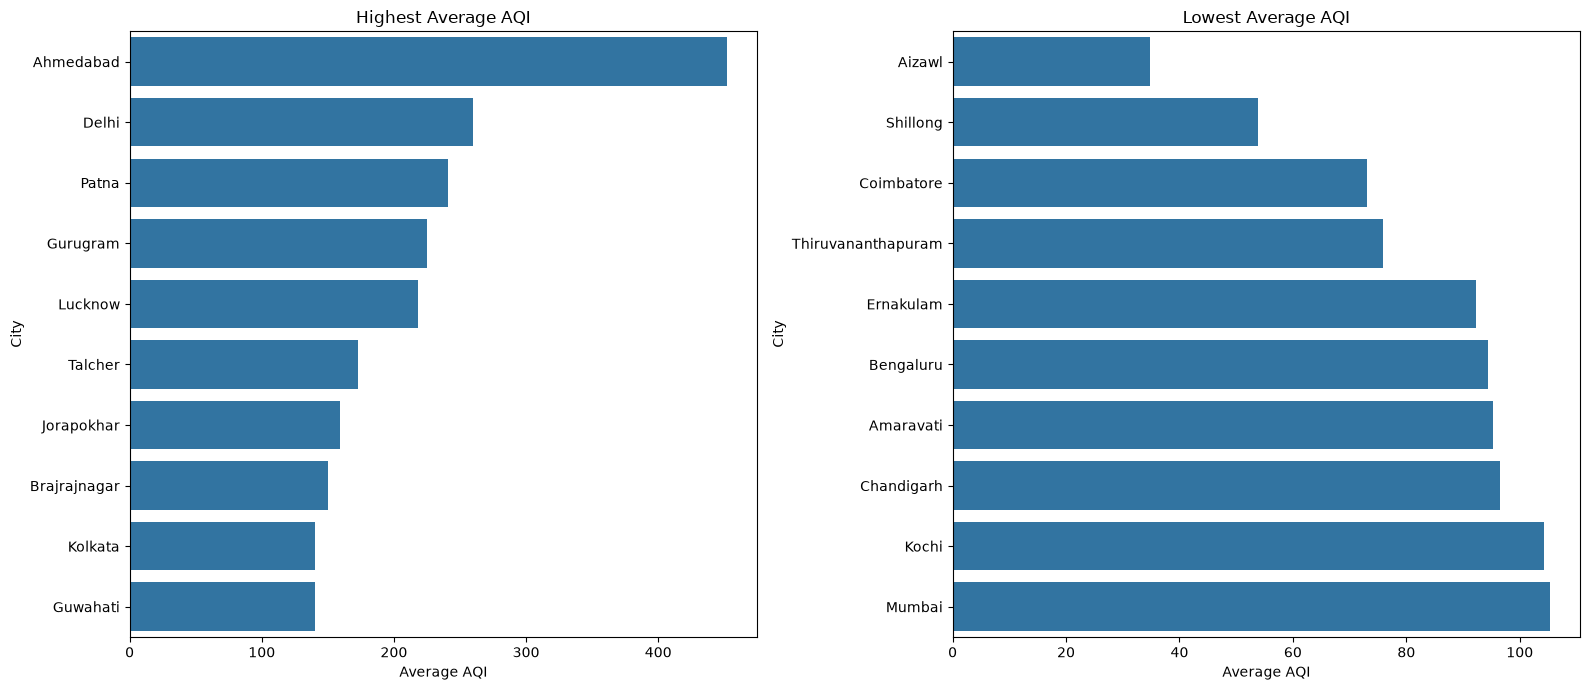

In [3]:

city_aqi = (
    df.groupby("City")
    .agg(
        Average_AQI=("AQI", "mean"),
        Median_AQI=("AQI", "median"),
        AQI_Records=("AQI", "count")
    )
    .dropna(subset=["Average_AQI"])
)

# Require at least 100 available AQI observations
eligible_cities = city_aqi[city_aqi["AQI_Records"] >= 100]

highest_aqi = eligible_cities.nlargest(10, "Average_AQI")
lowest_aqi = eligible_cities.nsmallest(10, "Average_AQI")

print("10 cities with highest average AQI")
display(highest_aqi.round(2))

print("10 cities with lowest average AQI")
display(lowest_aqi.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=highest_aqi.reset_index(),
    x="Average_AQI",
    y="City",
    ax=axes[0]
)
axes[0].set_title("Highest Average AQI")
axes[0].set_xlabel("Average AQI")

sns.barplot(
    data=lowest_aqi.reset_index(),
    x="Average_AQI",
    y="City",
    ax=axes[1]
)
axes[1].set_title("Lowest Average AQI")
axes[1].set_xlabel("Average AQI")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "highest_lowest_city_aqi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

highest_aqi.to_csv(TABLES_DIR / "highest_average_aqi_cities.csv")
lowest_aqi.to_csv(TABLES_DIR / "lowest_average_aqi_cities.csv")


,Average_AQI,Median_AQI,Available_Records
Season,,,
Winter,220.61,171.0,6243
Summer,147.67,115.0,7069
Monsoon,115.56,89.0,7713
Post-Monsoon,215.47,154.0,3825


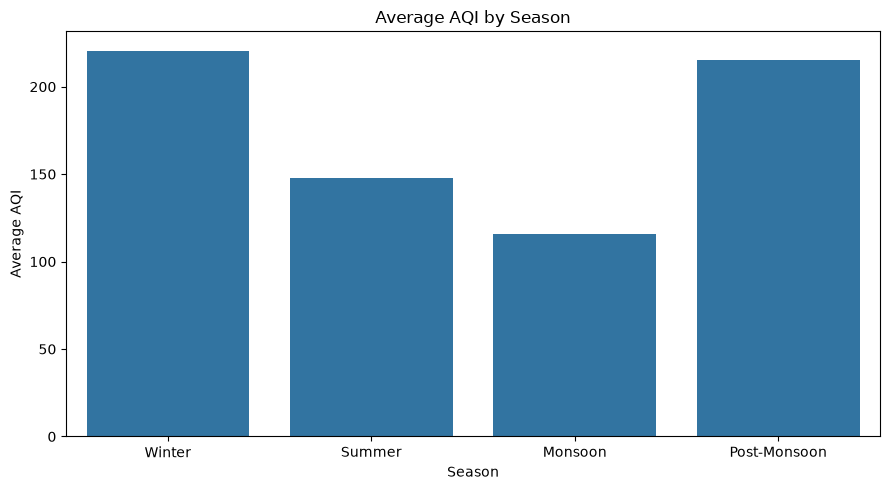

In [4]:

season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

seasonal_aqi = (
    df.groupby("Season")
    .agg(
        Average_AQI=("AQI", "mean"),
        Median_AQI=("AQI", "median"),
        Available_Records=("AQI", "count")
    )
    .reindex(season_order)
)

display(seasonal_aqi.round(2))

seasonal_aqi.to_csv(TABLES_DIR / "advanced_seasonal_aqi.csv")

plt.figure(figsize=(9, 5))
sns.barplot(
    data=seasonal_aqi.reset_index(),
    x="Season",
    y="Average_AQI"
)
plt.title("Average AQI by Season")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "advanced_seasonal_aqi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


,Average_AQI,Median_AQI,Available_Records
Month,,,
1,231.67,183.0,2141
2,202.91,149.5,2078
3,164.74,124.0,2327
4,143.36,111.0,2295
5,135.49,111.0,2447
6,120.20,96.0,2344
7,111.85,86.0,1836
8,113.61,85.0,1776
9,115.19,88.0,1757


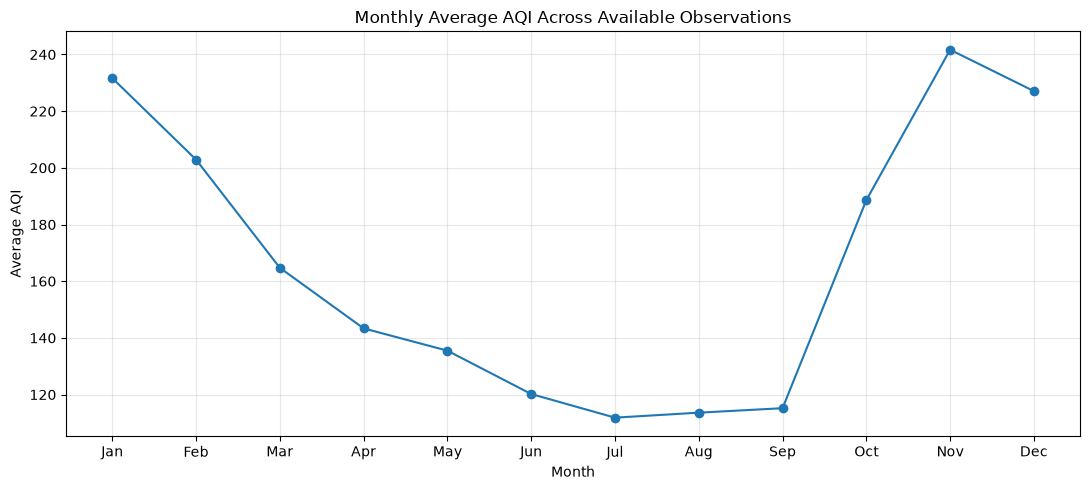

In [5]:

monthly_aqi = (
    df.groupby("Month")
    .agg(
        Average_AQI=("AQI", "mean"),
        Median_AQI=("AQI", "median"),
        Available_Records=("AQI", "count")
    )
    .reindex(range(1, 13))
)

display(monthly_aqi.round(2))
monthly_aqi.to_csv(TABLES_DIR / "advanced_monthly_aqi.csv")

plt.figure(figsize=(11, 5))
plt.plot(
    monthly_aqi.index,
    monthly_aqi["Average_AQI"],
    marker="o"
)
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.title("Monthly Average AQI Across Available Observations")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "advanced_monthly_aqi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


,Year,City,Average_AQI,Available_Records
0,2015,Delhi,297.02,365
1,2016,Delhi,301.37,365
2,2017,Delhi,256.73,356
3,2017,Jaipur,156.14,181
4,2018,Delhi,249.16,365
5,2018,Jaipur,150.03,365
6,2019,Chandigarh,135.55,117
7,2019,Delhi,232.10,365
8,2019,Guwahati,127.56,312
9,2019,Jaipur,120.51,365


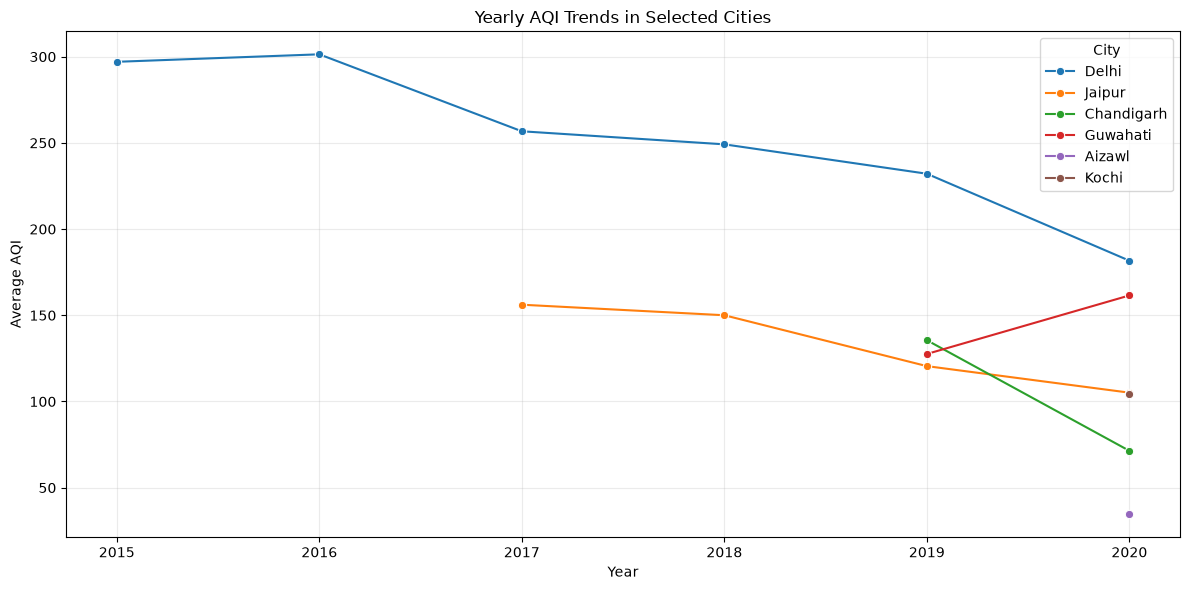

In [6]:

selected_cities = city_quality.head(6).index.tolist()

city_year_aqi = (
    df[df["City"].isin(selected_cities)]
    .groupby(["Year", "City"])
    .agg(
        Average_AQI=("AQI", "mean"),
        Available_Records=("AQI", "count")
    )
    .reset_index()
)

display(city_year_aqi.round(2))

city_year_aqi.to_csv(
    TABLES_DIR / "selected_city_yearly_aqi.csv",
    index=False
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=city_year_aqi,
    x="Year",
    y="Average_AQI",
    hue="City",
    marker="o"
)
plt.title("Yearly AQI Trends in Selected Cities")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "selected_city_yearly_aqi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


,Pollutant,Pearson_Correlation,Spearman_Correlation,Paired_Observations
1,PM10,0.803,0.871,17764
6,CO,0.683,0.549,24405
0,PM2.5,0.659,0.846,24172
3,NO2,0.537,0.462,24459
7,SO2,0.491,0.379,24245
4,NOx,0.486,0.485,22993
2,NO,0.452,0.470,24463
10,Toluene,0.280,0.367,19024
5,NH3,0.252,0.366,18314
8,O3,0.199,0.281,24043


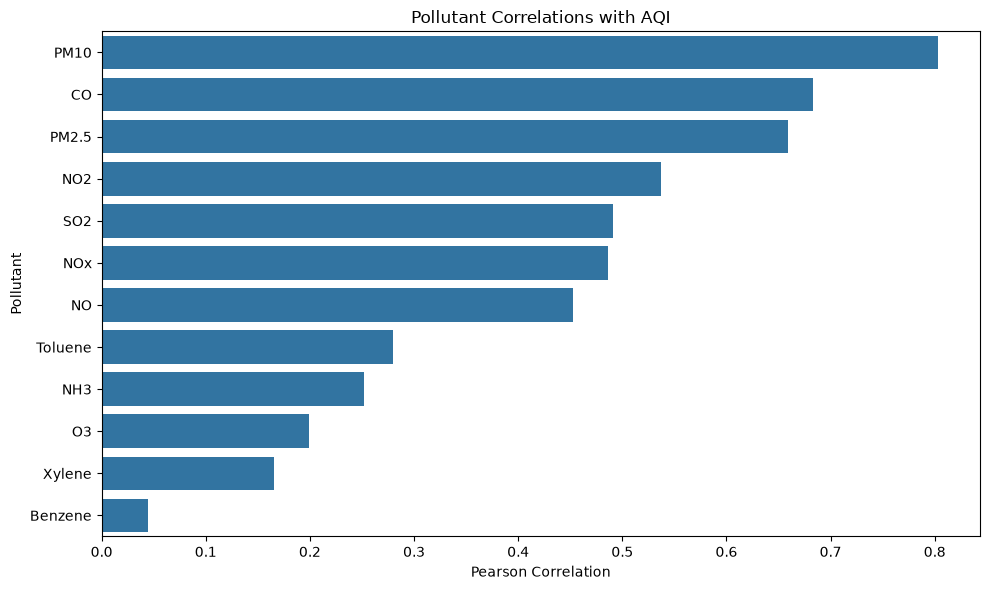

In [7]:

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "archive-3" / "city_day.csv"
raw_df = pd.read_csv(RAW_DATA_PATH)

pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]

results = []

for pollutant in pollutants:
    pair = raw_df[[pollutant, "AQI"]].dropna()

    if len(pair) >= 30:
        results.append({
            "Pollutant": pollutant,
            "Pearson_Correlation": pair[pollutant].corr(pair["AQI"]),
            "Spearman_Correlation": pair[pollutant].corr(
                pair["AQI"], method="spearman"
            ),
            "Paired_Observations": len(pair)
        })

correlation_results = pd.DataFrame(results).sort_values(
    "Pearson_Correlation",
    ascending=False
)

display(correlation_results.round(3))

correlation_results.to_csv(
    TABLES_DIR / "pollutant_aqi_correlations_raw_observations.csv",
    index=False
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=correlation_results,
    x="Pearson_Correlation",
    y="Pollutant"
)
plt.title("Pollutant Correlations with AQI")
plt.xlabel("Pearson Correlation")
plt.ylabel("Pollutant")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "pollutant_aqi_correlations.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [8]:

valid_aqi = df.dropna(subset=["AQI"])

findings = {
    "Total_City_Day_Records": len(df),
    "Number_of_Cities": df["City"].nunique(),
    "Available_AQI_Records": len(valid_aqi),
    "Overall_Average_AQI": valid_aqi["AQI"].mean(),
    "Overall_Median_AQI": valid_aqi["AQI"].median(),
    "Highest_Observed_AQI": valid_aqi["AQI"].max(),
    "Lowest_Observed_AQI": valid_aqi["AQI"].min(),
    "Highest_Average_AQI_City": city_aqi["Average_AQI"].idxmax(),
    "Lowest_Average_AQI_City": city_aqi["Average_AQI"].idxmin(),
    "Highest_Average_AQI": city_aqi["Average_AQI"].max(),
    "Lowest_Average_AQI": city_aqi["Average_AQI"].min(),
}

findings_df = pd.DataFrame(
    findings.items(),
    columns=["Metric", "Value"]
)

display(findings_df.round(2))

findings_df.to_csv(
    TABLES_DIR / "advanced_analysis_key_findings.csv",
    index=False
)

print("Advanced analysis complete.")
print("Figures saved to:", FIGURES_DIR)
print("Tables saved to:", TABLES_DIR)


,Metric,Value
0,Total_City_Day_Records,29531
1,Number_of_Cities,26
2,Available_AQI_Records,24850
3,Overall_Average_AQI,166.463581
4,Overall_Median_AQI,118.0
5,Highest_Observed_AQI,2049.0
6,Lowest_Observed_AQI,13.0
7,Highest_Average_AQI_City,Ahmedabad
8,Lowest_Average_AQI_City,Aizawl
9,Highest_Average_AQI,452.122939


Advanced analysis complete.
Figures saved to: /Users/ashokreddy/india-air-pollution-analysis/outputs/figures
Tables saved to: /Users/ashokreddy/india-air-pollution-analysis/outputs/tables
